## 0. Data

In [1]:
url = "http://byungwan.com/class/House_Prices.xls"

In [2]:
import pandas as pd

In [3]:
house = pd.read_excel(url)

In [4]:
house

,HomeID,Price,SqFt,Bedrooms,Bathrooms,Offers,Brick,Neighborhood
0,1,114300,1790,2,2,2,No,East
1,2,114200,2030,4,2,3,No,East
2,3,114800,1740,3,2,1,No,East
3,4,94700,1980,3,2,3,No,East
4,5,119800,2130,3,3,3,No,East
...,...,...,...,...,...,...,...,...
123,124,119700,1900,3,3,3,Yes,East
124,125,147900,2160,4,3,3,Yes,East
125,126,113500,2070,2,2,2,No,North
126,127,149900,2020,3,3,1,No,West


In [5]:
house.shape

(128, 8)

In [7]:
house.isnull().values.any()

np.False_

In [8]:
house2 = pd.get_dummies(house, columns=["Brick", "Neighborhood"], drop_first=True, dtype=int)

In [9]:
house2.head(10)

,HomeID,Price,SqFt,Bedrooms,Bathrooms,Offers,Brick_Yes,Neighborhood_North,Neighborhood_West
0,1,114300,1790,2,2,2,0,0,0
1,2,114200,2030,4,2,3,0,0,0
2,3,114800,1740,3,2,1,0,0,0
3,4,94700,1980,3,2,3,0,0,0
4,5,119800,2130,3,3,3,0,0,0
5,6,114600,1780,3,2,2,0,1,0
6,7,151600,1830,3,3,3,1,0,1
7,8,150700,2160,4,2,2,0,0,1
8,9,119200,2110,4,2,3,0,0,0
9,10,104000,1730,3,3,3,0,0,0


## 1. Simple Linear Regression

In [11]:
house2.columns.get_loc("Price")

1

In [12]:
y = house2.iloc[:,1]

In [16]:
x = house2.iloc[:,2]

In [18]:
from statsmodels import api as sm

In [21]:
reg = sm.OLS(y, x).fit()

In [22]:
print(reg.summary())

                                 OLS Regression Results                                
Dep. Variable:                  Price   R-squared (uncentered):                   0.972
Model:                            OLS   Adj. R-squared (uncentered):              0.972
Method:                 Least Squares   F-statistic:                              4390.
Date:                Tue, 22 Sep 2026   Prob (F-statistic):                   2.30e-100
Time:                        10:56:02   Log-Likelihood:                         -1463.3
No. Observations:                 128   AIC:                                      2929.
Df Residuals:                     127   BIC:                                      2932.
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------

In [23]:
x_c = sm.add_constant(x)

In [25]:
reg2 = sm.OLS(y, x_c).fit()

In [27]:
print(reg2.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.306
Model:                            OLS   Adj. R-squared:                  0.300
Method:                 Least Squares   F-statistic:                     55.50
Date:                Tue, 22 Sep 2026   Prob (F-statistic):           1.30e-11
Time:                        11:08:43   Log-Likelihood:                -1463.2
No. Observations:                 128   AIC:                             2930.
Df Residuals:                     126   BIC:                             2936.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1.009e+04    1.9e+04     -0.532      0.5

In [28]:
house.head(10)

,HomeID,Price,SqFt,Bedrooms,Bathrooms,Offers,Brick,Neighborhood
0,1,114300,1790,2,2,2,No,East
1,2,114200,2030,4,2,3,No,East
2,3,114800,1740,3,2,1,No,East
3,4,94700,1980,3,2,3,No,East
4,5,119800,2130,3,3,3,No,East
5,6,114600,1780,3,2,2,No,North
6,7,151600,1830,3,3,3,Yes,West
7,8,150700,2160,4,2,2,No,West
8,9,119200,2110,4,2,3,No,East
9,10,104000,1730,3,3,3,No,East


In [29]:
x2 = house2.iloc[:, 2:]

In [30]:
x2.head()

,SqFt,Bedrooms,Bathrooms,Offers,Brick_Yes,Neighborhood_North,Neighborhood_West
0,1790,2,2,2,0,0,0
1,2030,4,2,3,0,0,0
2,1740,3,2,1,0,0,0
3,1980,3,2,3,0,0,0
4,2130,3,3,3,0,0,0


In [31]:
reg3 = sm.OLS(y, x2).fit()

In [33]:
print(reg3.summary()) #if p>|t| is less than 0.05, it is significant, otherwise, not significant ex.) Neighborhood_North

                                 OLS Regression Results                                
Dep. Variable:                  Price   R-squared (uncentered):                   0.995
Model:                            OLS   Adj. R-squared (uncentered):              0.994
Method:                 Least Squares   F-statistic:                              3239.
Date:                Tue, 22 Sep 2026   Prob (F-statistic):                   2.09e-134
Time:                        11:21:24   Log-Likelihood:                         -1356.7
No. Observations:                 128   AIC:                                      2727.
Df Residuals:                     121   BIC:                                      2747.
Df Model:                           7                                                  
Covariance Type:            nonrobust                                                  
                         coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------

## Multicollinearity

In [34]:
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif

In [37]:
vif(x2.values, 1)

np.float64(31.028044452273534)

In [43]:
float(vif(x2.values, 1))

31.028044452273534

In [39]:
vif_values = [float(vif(x2.values, i)) for i in range(0, 7)]

In [42]:
vif_labels = x2.columns

In [44]:
pd.DataFrame({"Variable": vif_labels, "VIF Factor": vif_values})

,Variable,VIF Factor
0,SqFt,57.607757
1,Bedrooms,31.028044
2,Bathrooms,35.632902
3,Offers,10.591656
4,Brick_Yes,1.637724
5,Neighborhood_North,2.121365
6,Neighborhood_West,2.436297


In [45]:
corrs = house2.corr()

In [46]:
from matplotlib import pyplot as plt
import seaborn as sns

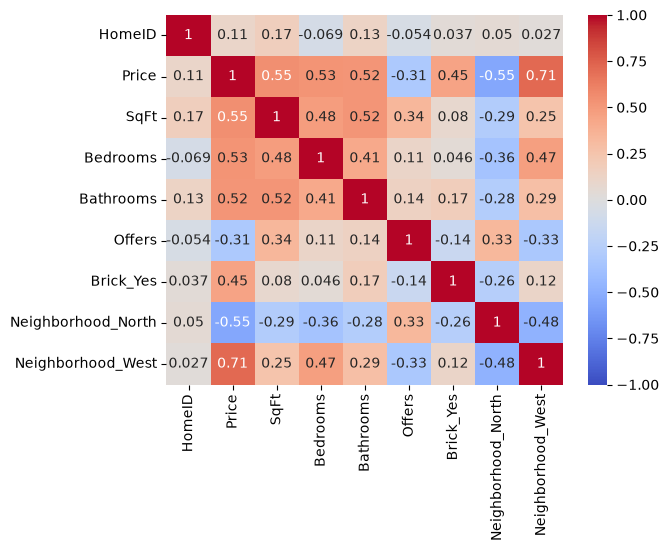

In [56]:
sns.heatmap(corrs, vmin=-1, vmax=1, center=0, cmap="coolwarm", annot=True)
plt.show()

In [58]:
x2r = house2.iloc[:, [2,6,7,8]]